# 04 — CNN

Our first network: a small CNN trained from scratch on spectrogram windows, in two versions.

- **plain**: the log spectrogram (25–800 Hz) as one input channel;
- **3-channel**: the spectrogram plus its split into the part that repeats with the heartbeat (heart and
  murmur) and the leftover (noise), from the not-beat-locked lane of notebook 02. The network gets to learn
  from the split itself instead of from one number per recording.

Each version is trained 3 times with different seeds (5 folds each, 30 networks). Every score is
out-of-fold over the 753 training patients; the test split is not touched.

`RECOMPUTE = True` retrains all 30 networks (GPU, about 20 min per seed and version, 2 h in total; the
3-channel input needs ~2 GB of RAM for its cache) and overwrites `results/cnn/`. `False` reads the stored
predictions, training curves and weights there.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from murmur.core.constants import CLASSES
from murmur.core.metric import confusion, weighted_accuracy
from murmur.core.paths import results_dir
from murmur.data import circor, segments
from murmur.evaluate import decisions
from murmur.models import patient
from murmur.models.cnn import SmallCNN
from murmur.preprocess import windows
from murmur.train import cv

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
RECOMPUTE = False
VERSIONS = {"plain": "spectrogram", "3-channel": "repet"}
SEEDS = [0, 1, 2]
run_dir = lambda version, seed: results_dir() / "cnn" / version / f"seed{seed}"

train, patients, train_recs, patient_of, _ = cv.training_set()

## The input

Each recording becomes a log spectrogram from 25 to 800 Hz (where heart sounds and murmurs live) at 100
frames per second, standardised per recording. The network sees **3-second windows** (300 frames, a new one
every 1.5 s) and predicts Present/Unknown/Absent for each. A recording's prediction is the average over its
windows.

For the 3-channel version, every heartbeat is stretched to a common length (using the S1 positions of the
segmentation) and compared with its neighbouring beats: what they share is the repeating part, the rest is
the leftover. A crying infant:

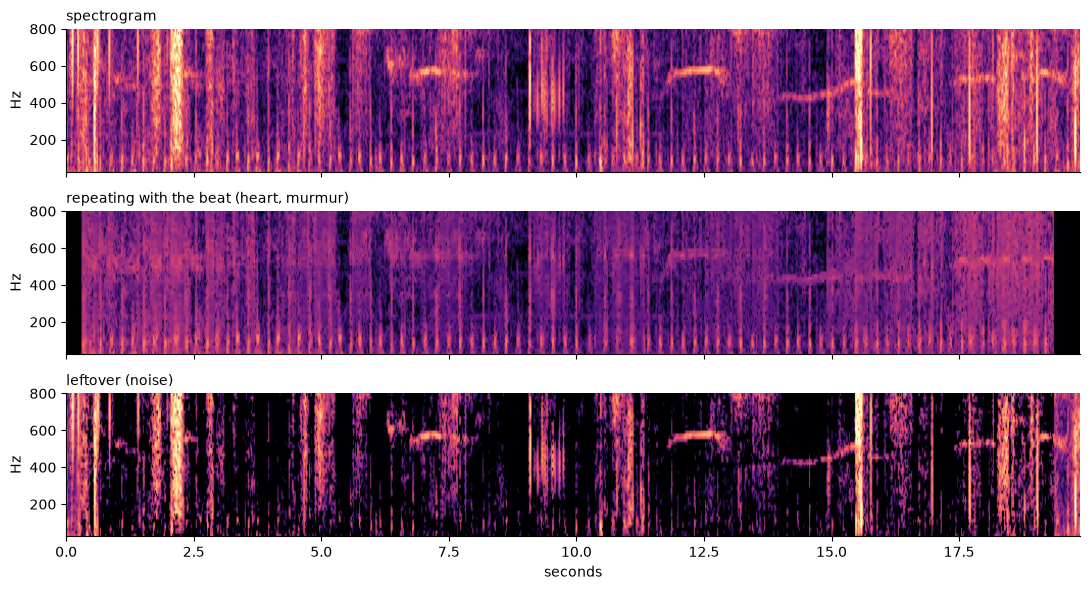

In [2]:
rid = "84900_MV"
rec = circor.recordings().loc[rid]
s1 = [s for s, _ in segments.intervals(circor.segmentation(rec), 1)]
ch = windows.repet_channels(circor.audio(rec), s1)
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, m, name in zip(axes, ch, ["spectrogram", "repeating with the beat (heart, murmur)", "leftover (noise)"]):
    ax.imshow(m, origin="lower", aspect="auto", cmap="magma", vmin=-2, vmax=3,
              extent=[0, m.shape[1] / windows.FPS, windows.FMIN, windows.FMAX])
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_ylabel("Hz")
axes[-1].set_xlabel("seconds")
plt.tight_layout()
plt.show()

The regular heartbeat stays in the middle row. Most of the crying (the curved lines at 400–600 Hz) and the
bumps (the bright vertical lines) move to the bottom one. The black edges are where there are not enough
beats on both sides to compare with.

## The network and its training

Four convolution blocks (16, 32, 64, 128 filters, 3×3), global average pooling, dropout 0.3 and a linear layer:
about 100 000 weights, kept small because there are only ~750 patients.

- loss: cross-entropy weighted like the metric (Present 5, Unknown 3, Absent 1);
- every recording carries its patient's label;
- AdamW, learning rate 1e-3, batches of 64 windows;
- early stopping: 15 % of the training patients are held aside, the network is scored on them by the
  patient-level WA after every epoch, and training stops 8 epochs after the best one (at most 40).

In [3]:
for version in VERSIONS:
    print(version, f"{sum(p.numel() for p in SmallCNN(in_channels=3 if version == '3-channel' else 1).parameters()):,} weights")
if RECOMPUTE:
    for version, inputs in VERSIONS.items():
        for seed in SEEDS:
            cv.run(run_dir(version, seed), inputs, repeat=seed)

plain 98,019 weights
3-channel 98,307 weights


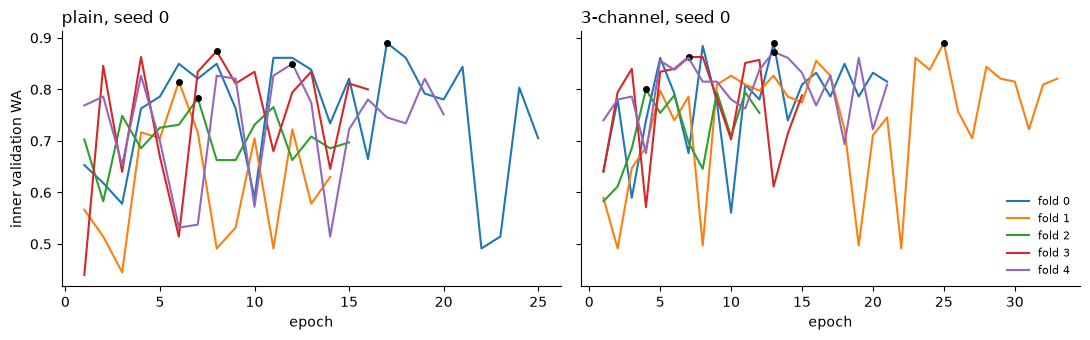

best_epoch  epochs_run  seconds
plain     seed 0        10.0        18.0    217.1
          seed 1         5.4        13.4    161.0
          seed 2         8.4        16.4    196.6
3-channel seed 0        12.4        20.4    284.0
          seed 1         8.6        16.6    229.5
          seed 2        10.6        18.6    262.1

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, version in zip(axes, VERSIONS):
    for fold in range(5):
        h = pd.read_csv(run_dir(version, 0) / f"history-fold{fold}.tsv", sep="\t")
        ax.plot(h["epoch"], h["val_wa"], label=f"fold {fold}")
        best = h.loc[h["val_wa"].idxmax()]
        ax.plot(best["epoch"], best["val_wa"], "k.", ms=8)
    ax.set_title(f"{version}, seed 0", loc="left")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("inner validation WA")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
pd.concat({v: pd.DataFrame([pd.read_json(run_dir(v, s) / "summary.json")[["best_epoch", "epochs_run", "seconds"]]
                                       .mean().rename(f"seed {s}") for s in SEEDS]) for v in VERSIONS}).round(1)

The best epoch (black dot) usually comes early, between 5 and 15; after that the network starts memorising
the training patients. The validation WA jumps by up to 0.3 between epochs, because the inner validation
set has only about 110 patients, of whom ~8 are Unknown. So the stopping point is partly luck, one more
reason to average several runs.

## From recordings to patients

A patient has about 3–4 recordings, one per auscultation position, and a murmur is often heard at only some
of them. So the patient's Present probability is the **highest** over their recordings, and Unknown and
Absent are averaged. The decision is the class with the highest probability. Taking the mean for Present too
(seed 0 of each version):

In [5]:
oof = lambda version, seed: pd.read_csv(run_dir(version, seed) / "oof-recordings.tsv", sep="\t",
                                       index_col="recording_id")[list(CLASSES)]
y = patients.loc[train.index, "murmur"]
rows = {}
for version in VERSIONS:
    r = oof(version, 0)
    mean_all = r.groupby(patient_of.loc[r.index].to_numpy()).mean()
    rows[version] = {"max for Present (used)": weighted_accuracy(y, patient.decide(patient.aggregate(r, patient_of)).loc[y.index]),
                     "mean for all": weighted_accuracy(y, patient.decide(mean_all).loc[y.index])}
pd.DataFrame(rows).T.round(3)

,max for Present (used),mean for all
plain,0.768,0.735
3-channel,0.778,0.774


The maximum matters for the plain version (+0.03) and makes little difference for the 3-channel one; it is kept for both.

## Plain vs 3-channel

One training run is not enough to compare: with ~150 patients per fold, a different seed moves a fold's WA
by a few points. So each version was trained with 3 seeds, and the rule was set **before** the extra seeds
ran: the 3-channel version is kept if its WA, averaged over the seeds, is higher in **at least 4 of the 5
folds**.

In [6]:
probs = {v: decisions.seeds([run_dir(v, s) for s in SEEDS], patient_of) for v in VERSIONS}
idx = probs["plain"][0].index
y, folds = patients.loc[idx, "murmur"], train.loc[idx, "fold"]
per_fold = {v: np.mean([decisions.fold_wa(p, y, folds) for p in probs[v]], axis=0) for v in VERSIONS}
table = pd.DataFrame({v: {**{f"seed {s}": weighted_accuracy(y, patient.decide(p)) for s, p in zip(SEEDS, probs[v])},
                          **{f"fold {k} (seed mean)": w for k, w in enumerate(per_fold[v])},
                          "seed ensemble": weighted_accuracy(y, patient.decide(decisions.ensemble(probs[v])))}
                      for v in VERSIONS})
wins = int((per_fold["3-channel"] > per_fold["plain"]).sum())
print(f"3-channel wins {wins} of 5 folds, mean difference {np.mean(per_fold['3-channel'] - per_fold['plain']):+.3f}")
table.round(3)

3-channel wins 4 of 5 folds, mean difference +0.014


,plain,3-channel
seed 0,0.768,0.778
seed 1,0.763,0.773
seed 2,0.773,0.795
fold 0 (seed mean),0.780,0.792
fold 1 (seed mean),0.753,0.774
fold 2 (seed mean),0.775,0.759
fold 3 (seed mean),0.793,0.826
fold 4 (seed mean),0.738,0.758
seed ensemble,0.785,0.814


**3-channel is kept.** It wins 4 of 5 folds, and each of its seeds beats each plain seed overall.

The **seed ensemble** averages the 3 runs' probabilities. It adds 2–3 points to either version, more than
the difference between them, so the final model will be an ensemble of several training runs.

Patient-level confusion of the two seed ensembles (rows true, columns predicted):

In [7]:
for v in VERSIONS:
    pred = patient.decide(decisions.ensemble(probs[v]))
    display(pd.DataFrame(confusion(y, pred), index=[f"true {c}" for c in CLASSES],
                         columns=[f"pred {c}" for c in CLASSES]).rename_axis(v))

,pred Present,pred Unknown,pred Absent
plain,,,
true Present,120,1,22
true Unknown,11,7,36
true Absent,43,9,504


,pred Present,pred Unknown,pred Absent
3-channel,,,
true Present,127,2,14
true Unknown,10,13,31
true Absent,46,17,493


The 3-channel version finds more Present and almost twice the Unknown, at the cost of more healthy
patients flagged. With the metric's weights, a Present or Unknown patient caught is worth more than an
Absent one lost.

## Adjusting the decision afterwards (did not help)

Four ways to adjust the decision on top of the CNN's probabilities were tried. Each is fitted on four folds'
patients and applied to the fifth, so none sees the patients it is scored on:

- **A, tuned multipliers**: scale the Present and Unknown probabilities by the factors that maximise WA;
- **C, recalibrated**: a logistic regression on the log probabilities, weighted like the metric;
- **B, + noise lanes**: C, plus the tagger's heart-likeness, the not-beat-locked level and the voice share
  (notebook 02) as extra inputs;
- **D, + infant**: B, plus whether the patient is an infant.

C, B and D are followed by A's multipliers. On the seed ensembles:

In [8]:
lane_table = pd.read_csv(results_dir() / "noise-lanes" / "recordings.tsv", sep="\t", index_col="recording_id")
extra = decisions.patient_extra(lane_table, patient_of, patients, idx)
lanes = ["tagger_heart_mean", "nbl_median", "voice_share"]
rows = []
for v in VERSIONS:
    p = decisions.ensemble(probs[v])
    rows += [{"version": v, **decisions.score("argmax (used)", y, patient.decide(p), folds)},
             {"version": v, **decisions.score("A tuned multipliers", y, decisions.nested_decide(p, y, folds), folds)}]
    for name, cols in [("C recalibrated", None), ("B + noise lanes", lanes), ("D + lanes + infant", lanes + ["infant"])]:
        f = decisions.fused(p, None if cols is None else extra[cols], y, folds)
        rows.append({"version": v, **decisions.score(name, y, decisions.nested_decide(f, y, folds), folds)})
pd.DataFrame(rows).drop(columns=["confusion", "fold mean"]).set_index(["version", "decision"]).round(3)

WA  fold sd  \
version   decision                              
plain     argmax (used)        0.785    0.030   
          A tuned multipliers  0.775    0.028   
          C recalibrated       0.764    0.042   
          B + noise lanes      0.761    0.033   
          D + lanes + infant   0.740    0.024   
3-channel argmax (used)        0.814    0.023   
          A tuned multipliers  0.798    0.030   
          C recalibrated       0.779    0.035   
          B + noise lanes      0.779    0.036   
          D + lanes + infant   0.773    0.037   

                                                          per fold  \
version   decision                                                   
plain     argmax (used)        [0.789, 0.761, 0.782, 0.839, 0.754]   
          A tuned multipliers     [0.8, 0.74, 0.761, 0.815, 0.761]   
          C recalibrated       [0.796, 0.713, 0.751, 0.829, 0.732]   
          B + noise lanes       [0.775, 0.744, 0.74, 0.818, 0.725]   
          D + lanes + infant    [0.758, 0.727, 0.74, 0.773, 0.704]   
3-channel argmax (used)        [0.839, 0.785, 0.792, 0.843, 0.813]   
          A tuned multipliers  [0.839, 0.785, 0.792, 0.822, 0.754]   
          C recalibrated       [0.818, 0.782, 0.747, 0.818, 0.732]   
          B + noise lanes      [0.804, 0.775, 0.789, 0.815, 0.711]   
          D + lanes + infant   [0.779, 0.772, 0.792, 0.815, 0.704]   

                               Present caught  Unknown caught  Absent caught  
version   decision                                                            
plain     argmax (used)                   120               7            504  
          A tuned multipliers             123              13            457  
          C recalibrated                  125               9            443  
          B + noise lanes                 118               8            476  
          D + lanes + infant              115              15            441  
3-channel argmax (used)                   127              13            493  
          A tuned multipliers             123              11            496  
          C recalibrated                  122              12            471  
          B + noise lanes                 119              15            476  
          D + lanes + infant              120              13            468

**Every adjustment scores below the plain argmax**, for both versions. Each one learns from four folds'
patients something that does not carry over to the fifth: with ~150 patients per fold and ~11 Unknown,
even two multipliers overfit.
The noise information helps more as **input channels** to the network (the 3-channel version) than as extra
numbers at the decision.

## What this means

| finding | consequence |
|---|---|
| The CNN reaches 0.768 (plain), vs 0.655 for frozen pretrained features (notebook 03) | Training from scratch is the right main model |
| The 3-channel input wins 4 of 5 folds over 3 seeds (0.782 vs 0.768) | The input of the final CNN |
| Averaging 3 seeds: 0.814 vs 0.785 | The final model is a seed ensemble |
| Adjusting the decision afterwards does not help | Argmax of the averaged probabilities |
| Unknown is still the weak class: 13 of 54 caught | The open problem for the RNN (notebook 05) |

For reference, the best team in the 2022 challenge scored 0.780 on the hidden test set. Our numbers are
cross-validated on the public training data and are not directly comparable.